In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

In [2]:
from typing import Optional

def insert_image(ax, path: str, zoom: float = 0.1, pos: tuple[float, float] = (0.0, 0.0), color: Optional[np.ndarray] = None):
    '''
    '''
    
    # load image
    img = mpimg.imread(path)
    
    # if desired, recolour
    if color is not None:
        img[(img != 0).any(axis = -1)] = color
    
    # make image
    icon = OffsetImage(img, zoom = zoom)
    
    box = AnnotationBbox(
        icon,
        pos,
        xycoords = ax.transAxes,
        frameon = False
    )
    
    # add to axis
    ax.add_artist(box)

def insert_rdm(ax, cm, n_items: int, n_rdms: int, pos: tuple, template: np.ndarray | None = None, noise_level: float = 0.5, size: tuple = (0.2, 0.3), offset_x: float = 0.0125, offset_y: float = -0.025) -> None:
    """
    """
    
    x, y = pos
    w, h = size
    
    for i in range(n_rdms, 0, -1):
        if template is None:
            rdm = np.random.uniform(low = -1, high = 1, size = (n_items, n_items))
            rdm[np.arange(n_items),np.arange(n_items)] = 1.0
        else:
            rdm = template.copy()
            
            noise = noise_level * np.random.uniform(low = -1, high = 1, size = (n_items, n_items))
            tri_x, tri_y = np.triu_indices(rdm.shape[0], k = 1)
            rdm[tri_x,tri_y] += noise[tri_x,tri_y]
            rdm[tri_y,tri_x] += noise[tri_x,tri_y]
            rdm = np.clip(rdm, a_min = -1.0, a_max = 1.0)

        ax_i = ax.inset_axes([x + offset_x * i, y + offset_y * i, w, h])
        ax_i.axis('off')
        
        col = plots.colours.RDM1

        ax_i.imshow(rdm, vmin = -1, vmax = 1, cmap = cm)
        ax_i.plot([-0.5, n_items - 0.5], [-0.5, -0.5], color = col, linewidth = 1.5)
        ax_i.plot([-0.5, n_items - 0.5], [n_items - 0.5, n_items - 0.5], color = col, linewidth = 1.5)
        ax_i.plot([-0.5, -0.5], [-0.5, n_items - 0.5], color = col, linewidth = 1.5)
        ax_i.plot([n_items - 0.5, n_items - 0.5], [-0.5, n_items - 0.5], color = col, linewidth = 1.5)
        
        for j in range(n_items):
            ax_i.plot([j - 0.5, j - 0.5], [-0.5, n_items - 0.5], color = col, linewidth = 0.5)
            ax_i.plot([-0.5, n_items - 0.5], [j - 0.5, j - 0.5], color = col, linewidth = 0.5)

def insert_ma(ax, pos: tuple[float], size: tuple[float], alpha0 = 0.75, alpha1 = 0.25):
    """
    """
    
    ax_i = ax.inset_axes([*pos, *size])
    ax_i.axis('equal')
    ax_i.axis('off')
    ax_i.set_xlim([-1, 1])
    ax_i.set_ylim([-1, 1])
    
    x = np.linspace(0, 2 * np.pi, 100)
    y = np.sin(x)
    z = np.cos(x)
    
    ax_i.plot(y, z, color = col_axis, alpha = alpha0, clip_on = False)
    ax_i.fill_between(y, z, edgecolor = 'None', facecolor = 'black', alpha = alpha1)
    
    return ax_i

from typing import Dict, List
def annotate_ma(ax, annotations: Dict[str, np.ndarray], cut_a: List[str], cut_b: List[str], col_a = None, col_b = None):
    """
    """
    
    for name in annotations:
        xy, ha, va = annotations[name]
        alpha_a, color = (1.0, col_a) if name not in cut_a else (0.5, col_axis)
        if color is None:
            color = col_axis
        
        ax.annotate(name, xy = (0, 0), xytext = tuple(xy), ha = ha, va = va, color = color, alpha = alpha_a)
    
    for i, X in enumerate(annotations):
        for j, Y in enumerate(annotations):
            if i <= j: continue
            
            xx, _, _ = annotations[X]
            yy, _, _ = annotations[Y]
            
            alpha_a, ls, color = (1.0, '-', col_b) if (X not in cut_a) and (Y not in cut_a) and (f'{X}-{Y}' not in cut_b) and (f'{Y}-{X}' not in cut_b) else (0.5, '--', col_axis)
            if color is None:
                color = col_axis
            
            xx, yy = 0.9 * xx, 0.9 * yy
            
            ax.plot([xx[0], yy[0]], [xx[1], yy[1]], linewidth = 0.5, color = color, alpha = alpha_a, linestyle = ls)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


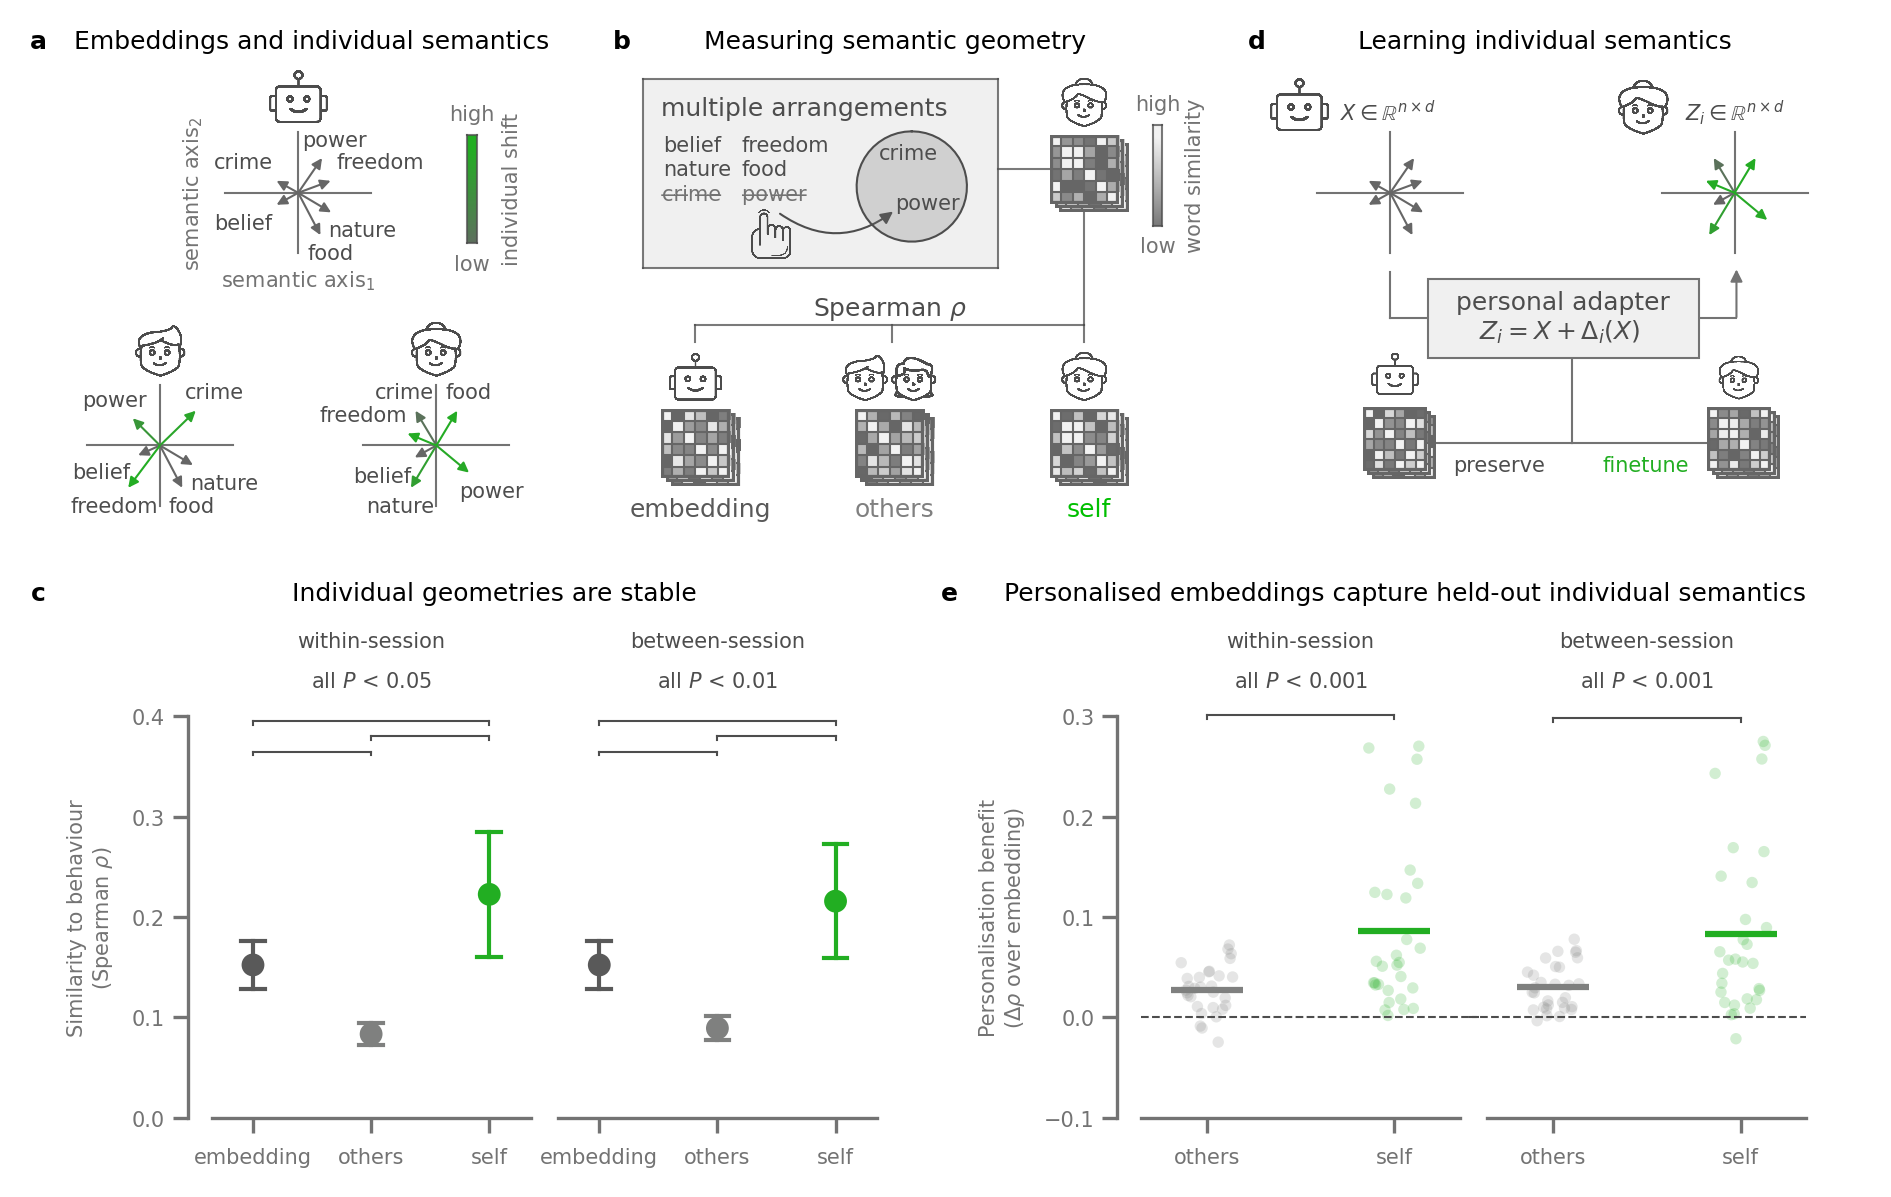

In [4]:
DEBUG_BORDERS = False
hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

run = 0
exp = 1
mod = 'glove'

# initialise plot
fig, ax = plt.subplots(figsize = (6.4, 4.0), dpi = 300)

# setup base canvases
cv1 = ax.inset_axes([0.0, 0.55, 0.3333, 0.45])
cv2 = ax.inset_axes([0.32, 0.55, 0.3333, 0.45])
cv3 = ax.inset_axes([0.66, 0.55, 0.3333, 0.45])

cv4 = ax.inset_axes([0.0, 0.0, 0.5, 0.55])
cv5 = ax.inset_axes([0.5, 0.0, 0.5, 0.55])

canvases = [ax, cv1, cv2, cv3, cv4, cv5]

for i, cv_i in enumerate(canvases):
    cv_i.set_xlim([0, 1])
    cv_i.set_ylim([0, 1])
    cv_i.axis('off')
    
    if DEBUG_BORDERS:
        cv_i.plot([0, 1], [0, 0], color = 'black')
        cv_i.plot([0, 0], [0, 1], color = 'black')
        cv_i.plot([1, 1], [0, 1], color = 'black')
        cv_i.plot([0, 1], [1, 1], color = 'black')

'''
panel A
'''

w, h = 0.8, 0.8

#cv1_a1 = cv1.inset_axes([0.095, 0.550, 0.3, 0.3])
#cv1_a2 = cv1.inset_axes([0.095, 0.050, 0.3, 0.3])
#cv1_a3 = cv1.inset_axes([0.550, 0.550, 0.3, 0.3])

cv1_a1 = cv1.inset_axes([0.2775, 0.550, 0.3, 0.3])
cv1_a2 = cv1.inset_axes([0.050, 0.050, 0.3, 0.3])
cv1_a3 = cv1.inset_axes([0.505, 0.050, 0.3, 0.3])

cv1_as = [cv1_a1, cv1_a2, cv1_a3]

raster_args = dict(
    color = plots.colours.H3,
    lw = 0.5,
    ls = '-'
)

word_args = dict(
    fontsize = 5,
    color = plots.colours.H2,
    ha = 'center',
    va = 'center',
    annotation_clip = False
)

arrow_args = dict(
    arrowprops = dict(
        arrowstyle = '<|-',
        color = plots.colours.H2,
        shrinkA = 0.0,
        shrinkB = 0.0,
        lw = 0.5
    )
)

words = np.array(['crime', 'nature', 'belief', 'power', 'food', 'freedom'])
pos = np.array([
    [-0.6, 0.4],
    [0.7, -0.5],
    [-0.6, -0.4],
    [0.40, 0.7],
    [0.35, -0.8],
    [0.9, 0.4]
])

offsets = np.zeros((3, 6, 2))
offsets[1] = np.array([
    [1.2, 0.3],
    [0.0, 0.0],
    [-0.05, 0.05],
    [-0.9, -0.1],
    [0.0, 0.0],
    [-1.4, -1.2]
])
offsets[2] = np.array([
    [0.25, 0.3],
    [-1.1, -0.3],
    [0.0, 0.0],
    [0.2, -1.3],
    [0.0, 1.5],
    [-1.7, 0.0]
])

for i, cv_i in enumerate(cv1_as):
    cv_i.set_xlim([-1, 1])
    cv_i.set_ylim([-1, 1])
    cv_i.axis('off')
    
    cv_i.plot([-w, w], [0, 0], **raster_args)
    cv_i.plot([0, 0], [-h, h], **raster_args)
    
    for j in range(len(words)):
        word_ij = words[j]
        pos_ij = pos[j] + offsets[i,j]
        
        v_a = pos_ij / np.linalg.norm(pos_ij, axis = -1)
        v_b = pos[j] / np.linalg.norm(pos[j], axis = -1)
        
        diff_ij = 0.5 - (v_a @ v_b) / 2
        diff_ij = 1 / (1 + np.exp(-5 * diff_ij))
        diff_ij = 2 * (diff_ij - 0.5)
        
        word_args_ij = deepcopy(word_args)
        arrow_args_ij = deepcopy(arrow_args)
        
        arrow_args_ij['arrowprops']['color'] = plots.colours.CM_RDM_HL(diff_ij)
        
        cv_i.annotate(word_ij, xy = (0, 0), xytext = tuple(pos_ij), **word_args_ij, **arrow_args_ij)

# axis labels
anno_args = deepcopy(word_args)
anno_args['color'] = plots.colours.H3

#cv1_a1.annotate('semantic\n'  + fr'dimension$_1$', xy = (0, 0), xytext = (0.0, -1.25), **anno_args)
#cv1_a1.annotate('semantic\n' + fr'dimension$_n$', xy = (0, 0), xytext = (-1.25, 0.0), **anno_args, rotation = 90)
cv1_a1.annotate(fr'semantic axis$_1$', xy = (0, 0), xytext = (0.0, -1.15), **anno_args)
cv1_a1.annotate(fr'semantic axis$_2$', xy = (0, 0), xytext = (-1.15, 0.0), **anno_args, rotation = 90)

# label each
insert_image(cv1_a1, './resources/robot.png', 0.05, (0.5, 1.125), color = plots.colours.H2)
insert_image(cv1_a2, './resources/human-1.png', 0.05, (0.5, 1.125), color = plots.colours.H2)
insert_image(cv1_a3, './resources/human-2.png', 0.05, (0.5, 1.125), color = plots.colours.H2)

# add colorbar
#cv1_cm = cv1.inset_axes([0.125, 0.675, 0.15, 0.0175])
#cv1_cm = cv1.inset_axes([0.705, 0.60, 0.0175, 0.225])
cv1_cm = cv1.inset_axes([0.705, 0.60, 0.0165, 0.215])

cv1_cm.set_xlim([0, 1])
cv1_cm.set_ylim([0, 1])
cv1_cm.axis('off')

outline_arg = dict(
    color = plots.colours.H2,
    alpha = 0.75,
    clip_on = False,
    lw = 0.5,
    ls = '-'
)

cv1_cm.plot([0, 0], [0, 1], **outline_arg)
cv1_cm.plot([1, 1], [0, 1], **outline_arg)
cv1_cm.plot([0, 1], [0, 0], **outline_arg)
cv1_cm.plot([0, 1], [1, 1], **outline_arg)

x = np.linspace(0, 1, 100)
y = np.linspace(0, 1, 100)
z = np.linspace(0, 1, 100)

cv1_cm.scatter(x, y, c = z, cmap = plots.colours.CM_RDM_HL)
#cv1_cm.annotate('individual shift', xy = (0, 0), xytext = (0.5, 2.0), ha = 'center', va = 'bottom', fontsize = 5, color = plots.colours.H3, rotation = 0)
#cv1_cm.annotate('low', xy = (0, 0), xytext = (-0.1, 0.5), ha = 'right', va = 'center', fontsize = 5, color = plots.colours.H3, rotation = 0)
#cv1_cm.annotate('high', xy = (0, 0), xytext = (1.1, 0.5), ha = 'left', va = 'center', fontsize = 5, color = plots.colours.H3, rotation = 0)
cv1_cm.annotate('individual shift', xy = (0, 0), xytext = (3.5, 0.5), ha = 'left', va = 'center', fontsize = 5, color = plots.colours.H3, rotation = 90)
cv1_cm.annotate('low', xy = (0, 0), xytext = (0.5, -0.1), ha = 'center', va = 'top', fontsize = 5, color = plots.colours.H3, rotation = 0)
cv1_cm.annotate('high', xy = (0, 0), xytext = (0.5, 1.1), ha = 'center', va = 'bottom', fontsize = 5, color = plots.colours.H3, rotation = 0)

'''
panel B
'''

# setup top canvases
cv2_a1 = cv2.inset_axes([0.035, 0.6, 0.325, 0.325])
cv2_a2 = cv2.inset_axes([0.315, 0.55, 0.325, 0.325])
cv2_a3 = cv2.inset_axes([0.615, 0.6, 0.325, 0.325])

cv2_a4 = cv2.inset_axes([-0.025, 0.025, 0.325, 0.325])
cv2_a5 = cv2.inset_axes([0.295, 0.025, 0.325, 0.325])
cv2_a6 = cv2.inset_axes([0.615, 0.025, 0.325, 0.325])

cv2_ta = [cv2_a1, cv2_a2, cv2_a3, cv2_a4, cv2_a5, cv2_a6]

for i, cv_i in enumerate(cv2_ta):
    cv_i.axis('off')
    if i == 1:
        cv_i.axis('equal')
    
    cv_i.set_xlim([0, 1])
    cv_i.set_ylim([0, 1])

# make top row
place = np.array(['crime', 'power'])
place_at = np.array([
    [0.3, 0.7],
    [0.4, 0.4]
])

ct = np.linspace(0, 2 * np.pi)
cx = 0.5 + np.sin(ct) / 3
cy = 0.5 + np.cos(ct) / 3

cv2_a2.plot(cx, cy, color = plots.colours.H2, lw = 0.5)
cv2_a2.fill_between(cx, cy, edgecolor = 'None', facecolor = plots.colours.H3, alpha = 0.25)

ncols = 3
w = 0.40
h = 0.15
wo, ho = 0.1, 0.30

word_arg = dict(
    xy = (0, 0),
    fontsize = 5,
    color = plots.colours.H2,
    ha = 'left',
    va = 'center',
    annotation_clip = False
)

for i in range(len(words)):
    j, k = i // ncols, i % ncols
    x, y = wo + j * w, ho + k * h
    word = words[i]
    
    word_arg_i = deepcopy(word_arg)
    if word in place:
        # place word in circle
        indx = np.where(place == word)[0][0]
        xy = place_at[indx]
        cv2_a2.annotate(word, xytext = tuple(xy), **word_arg_i)
        
        # then alter
        word_arg_i['color'] = plots.colours.H3
        word = '\u0336'.join(word) + '\u0336'
    
    cv2_a1.annotate(word, xytext = (x, y), **word_arg_i)

# make annotation
arrow_prop = dict(
    ha = 'center',
    va = 'center',
    arrowprops = dict(
        arrowstyle = '<|-',
        connectionstyle = 'arc3,rad=-0.4',
        lw = 0.5,
        color = plots.colours.H2
    )
)

xy_a = np.array([wo + 1.4 * w, ho + -0.6 * h])
xy_b = np.array([1.3, 0.225])
cv2_a1.annotate('', xy = tuple(xy_a), xytext = tuple(xy_b), **arrow_prop)
insert_image(cv2_a1, './resources/click.png', 0.045, (0.65, 0.05), color = plots.colours.H2)

rdm_0 = pos + offsets[2]
rdm_0 = rdm_0 / np.linalg.norm(rdm_0, axis = -1, keepdims = True)
rdm_0 = rdm_0 @ rdm_0.T
insert_rdm(cv2_a3, plots.colours.CM_RDM_CL, 6, 3, (0.25, 0.20), template = rdm_0, size = (0.35, 0.55), offset_x = 0.025, offset_y = -0.025)
insert_image(cv2_a3, './resources/human-2.png', 0.045, (0.45, 0.85), color = plots.colours.H2)

insert_rdm(cv2_a6, plots.colours.CM_RDM_CL, 6, 3, (0.25, 0.30), template = rdm_0, size = (0.35, 0.55), offset_x = 0.025, offset_y = -0.025)
insert_image(cv2_a6, './resources/human-2.png', 0.045, (0.45, 0.95), color = plots.colours.H2)

rdm_1 = pos + offsets[1]
rdm_1 = rdm_1 / np.linalg.norm(rdm_1, axis = -1, keepdims = True)
rdm_1 = rdm_1 @ rdm_1.T
insert_rdm(cv2_a5, plots.colours.CM_RDM_CL, 6, 3, (0.25, 0.30), template = rdm_1, size = (0.35, 0.55), offset_x = 0.025, offset_y = -0.025)
insert_image(cv2_a5, './resources/human-1.png', 0.045, (0.325, 0.95), color = plots.colours.H2)
insert_image(cv2_a5, './resources/human-3.png', 0.045, (0.575, 0.95), color = plots.colours.H2)

rdm_2 = pos.copy()
rdm_2 = rdm_2 / np.linalg.norm(rdm_2, axis = -1, keepdims = True)
rdm_2 = rdm_2 @ rdm_2.T
insert_rdm(cv2_a4, plots.colours.CM_RDM_CL, 6, 3, (0.25, 0.30), template = rdm_2, size = (0.35, 0.55), offset_x = 0.025, offset_y = -0.025)
insert_image(cv2_a4, './resources/robot.png', 0.045, (0.45, 0.95), color = plots.colours.H2)

cv2_a1.fill_between([0.0, 1.8, 1.8, 0.0], [-0.15, -0.15, 1.0, 1.0], edgecolor = 'None', facecolor = plots.colours.H3, alpha = 0.10, clip_on = False)
cv2_a1.annotate('multiple arrangements', xy = (0, 0), xytext = (0.09, 0.825), ha = 'left', va = 'center', fontsize = 6, color = plots.colours.H2, annotation_clip = False)

line_arg = dict(
    color = plots.colours.H2,
    alpha = 0.75,
    clip_on = False,
    lw = 0.5,
    ls = '-'
)

cv2_a1.plot([0.0, 1.8], [-0.15, -0.15], **line_arg)
cv2_a1.plot([0.0, 1.8], [1.0, 1.0], **line_arg)
cv2_a1.plot([0.0, 0.0], [-0.15, 1.0], **line_arg)
cv2_a1.plot([1.8, 1.8], [-0.15, 1.0], **line_arg)
cv2_a1.plot([1.8, 2.4], [0.45, 0.45], **line_arg)

cv2_a3.plot([0.45, 0.45], [0.50, -0.50], **line_arg)
cv2_a3.plot([0.45, -1.520], [-0.50, -0.50], **line_arg)

cv2_a3.plot([0.45, 0.45], [-0.50, -0.60], **line_arg)
cv2_a3.plot([-0.525, -0.525], [-0.50, -0.60], **line_arg)
cv2_a3.plot([-1.520, -1.520], [-0.50, -0.60], **line_arg)

anno_arg = dict(
    xy = (0, 0),
    fontsize = 6,
    ha = 'center',
    va = 'center',
    annotation_clip = False
)

cv2_a3.annotate(fr'Spearman $\rho$', xytext = (-0.535, -0.40), color = plots.colours.H2, **anno_arg)
cv2_a6.annotate('self', xytext = (0.475, 0.15), color = plots.colours.HL3, **anno_arg)
cv2_a5.annotate('others', xytext = (0.475, 0.15), color = plots.colours.HL2, **anno_arg)
cv2_a4.annotate('embedding', xytext = (0.475, 0.15), color = plots.colours.HL1, **anno_arg)

cv2_cm = cv2.inset_axes([0.875, 0.635, 0.015, 0.2])
cv2_cm.set_xlim([0, 1])
cv2_cm.set_ylim([0, 1])
cv2_cm.axis('off')

cv2_cm.plot([0, 1], [0, 0], **line_arg)
cv2_cm.plot([0, 1], [1, 1], **line_arg)
cv2_cm.plot([0, 0], [0, 1], **line_arg)
cv2_cm.plot([1, 1], [0, 1], **line_arg)

x = np.linspace(0, 1, 100)
y = np.linspace(0, 1, 100)
z = np.linspace(0, 1, 100)

cv2_cm.scatter(x, y, c = z, cmap = plots.colours.CM_RDM_CL)
cv2_cm.annotate('word similarity', xy = (0, 0), xytext = (3.5, 0.5), ha = 'left', va = 'center', fontsize = 5, color = plots.colours.H3, rotation = 90)
cv2_cm.annotate('low', xy = (0, 0), xytext = (0.5, -0.1), ha = 'center', va = 'top', fontsize = 5, color = plots.colours.H3, rotation = 0)
cv2_cm.annotate('high', xy = (0, 0), xytext = (0.5, 1.1), ha = 'center', va = 'bottom', fontsize = 5, color = plots.colours.H3, rotation = 0)
        

'''
panel C
'''

cv3_a1 = cv3.inset_axes([0.095, 0.550, 0.3, 0.3])
cv3_a2 = cv3.inset_axes([0.662, 0.550, 0.3, 0.3])
cv3_a3 = cv3.inset_axes([0.095, 0.025, 0.3, 0.3])
cv3_a4 = cv3.inset_axes([0.662, 0.025, 0.3, 0.3])

cv3_as = [cv3_a1, cv3_a2, cv3_a3, cv3_a4]
w, h = 0.8, 0.8

for i, cv_i in enumerate(cv3_as):
    cv_i.set_xlim([-1, 1])
    cv_i.set_ylim([-1, 1])
    cv_i.axis('off')

    if i > 1: continue
    
    cv_i.plot([-w, w], [0, 0], **raster_args)
    cv_i.plot([0, 0], [-h, h], **raster_args)
    
    for j in range(len(words)):
        if i == 1: i = 2
        
        word_ij = words[j]
        pos_ij = pos[j] + offsets[i,j]
        
        v_a = pos_ij / np.linalg.norm(pos_ij, axis = -1)
        v_b = pos[j] / np.linalg.norm(pos[j], axis = -1)
        
        diff_ij = 0.5 - (v_a @ v_b) / 2
        diff_ij = 1 / (1 + np.exp(-5 * diff_ij))
        diff_ij = 2 * (diff_ij - 0.5)
        
        word_args_ij = deepcopy(word_args)
        arrow_args_ij = deepcopy(arrow_args)
        
        word_args_ij['color'] = 'white'
        arrow_args_ij['arrowprops']['color'] = plots.colours.CM_RDM_HL(diff_ij)
        
        cv_i.annotate(word_ij, xy = (0, 0), xytext = tuple(pos_ij), **word_args_ij, **arrow_args_ij)

# label each
insert_image(cv3_a1, './resources/robot.png', 0.05, (0.0, 1.075), color = plots.colours.H2)
insert_image(cv3_a2, './resources/human-2.png', 0.05, (0.0, 1.050), color = plots.colours.H2)

anno_arg = dict(
    xy = (0, 0),
    fontsize = 5,
    color = plots.colours.H2,
    ha = 'left',
    va = 'center',
    annotation_clip = False
)

cv3_a1.annotate(
    fr'$X\in\mathbb{{R}}^{{n\times d}}$',
    xytext = (-0.55, 1.075),
    **anno_arg
)

cv3_a2.annotate(
    fr'$Z_i\in\mathbb{{R}}^{{n\times d}}$',
    xytext = (-0.55, 1.075),
    **anno_arg
)

cv3_a1.annotate(
    '  personal adapter  \n' + fr'     $Z_i = X + \Delta_i(X)$  ', 
    xy = (0, 0), 
    xytext = (0.55, -1.65), 
    ha = 'left', 
    va = 'center', 
    fontsize = 6, 
    color = plots.colours.H2, 
    bbox = dict(
        facecolor = list(plots.colours.H3[:-1]) + [0.1], 
        edgecolor = plots.colours.H3, 
        pad = 3,
        lw = 0.5
    ), 
    annotation_clip = False
)

line_arg = dict(
    lw = 0.5,
    color = plots.colours.H3,
    ls = '-',
    clip_on = False
)

cv3_a1.plot([0.0, 0.0], [-1.05, -1.65], **line_arg)
cv3_a1.plot([0.0, 0.4], [-1.65, -1.65], **line_arg)
cv3_a1.plot([3.4, 3.8], [-1.65, -1.65], **line_arg)
cv3_a1.annotate(
    '',
    xy = (3.8, -0.9),
    xytext = (3.8, -1.75),
    ha = 'center',
    va = 'center',
    arrowprops = dict(
        arrowstyle = '-|>',
        color = line_arg['color'],
        lw = line_arg['lw']
    ),
    annotation_clip = False
)

cv3_a1.plot([2.0, 2.0], [-2.20, -3.30], **line_arg)
cv3_a1.plot([0.5, 2.0], [-3.30, -3.30], **line_arg)
cv3_a1.plot([2.0, 3.5], [-3.30, -3.30], **line_arg)

anno_arg['ha'] = 'center'
anno_arg['va'] = 'center'

cv3_a1.annotate(
    'preserve',
    xytext = (1.2, -3.60),
    **anno_arg
)

anno_arg['color'] = plots.colours.HL_SELF
cv3_a1.annotate(
    'finetune',
    #xytext = (2.9, -3.60),
    xytext = (2.8, -3.60),
    **anno_arg
)

insert_rdm(cv3_a3, plots.colours.CM_RDM_CL, 6, 3, (0.325, 0.375), template = rdm_2, size = (0.35, 0.55), offset_x = 0.025, offset_y = -0.025)
insert_image(cv3_a3, './resources/robot.png', 0.04, (0.525, 1.05), color = plots.colours.H2)

insert_rdm(cv3_a4, plots.colours.CM_RDM_CL, 6, 3, (0.325, 0.375), template = rdm_0, size = (0.35, 0.55), offset_x = 0.025, offset_y = -0.025)
insert_image(cv3_a4, './resources/human-2.png', 0.04, (0.525, 1.025), color = plots.colours.H2)

'''
panel D
'''

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

# within-session boards (5 folds)
cv4_a1 = cv4.inset_axes([0.19, 0.075, 0.35, 0.65])

R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-macrossreliability_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
R_base = 0.5 * R['rho_emb'].squeeze().cpu().numpy().diagonal() + 0.5 * R['rho_bme'].squeeze().cpu().numpy().diagonal()

R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-mareliability_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
#R_base = R['rho_emb'].squeeze().cpu().numpy().diagonal()
R_indiv = R['rho'].cpu().numpy().diagonal()
R_group = R['rho'].cpu().numpy()
R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

R_a = np.array([R_base, R_group, R_indiv])
R_d = R_a.copy()
X_jitter = np.random.uniform(-0.15, 0.15, size = (R_base.shape[0],))

offset = 0
ci_off = 0.1

for i, R_i in enumerate(R_d):
    mu = R_i.mean()
    se = model.stats.bootstrap_se(R_i)

    if offset < (mu + 1.96 * se):
        offset = mu + 1.96 * se
    
    cv4_a1.scatter([i], [mu], marker = 'o', edgecolor = 'None', facecolor = cols[i], s = 30, clip_on = False)
    cv4_a1.plot([i, i], [mu - 1.96 * se, mu + 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)
    cv4_a1.plot([i-ci_off, i+ci_off], [mu - 1.96 * se, mu - 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)
    cv4_a1.plot([i-ci_off, i+ci_off], [mu + 1.96 * se, mu + 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)

design = [(1, 0), (2, 1), (2, 0)]
group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(group, './deliverable/csv/fig1/d_wthn_group.csv')
model.stats.save_results(pairwise, './deliverable/csv/fig1/d_wthn_pairs.csv')

# significance
count = 0.0
gain = 0.015
min_p = 0.0
offset = 0.365

for i, (ii, jj) in enumerate(design):
    p_i = pairwise[i]['p_cor']
    if p_i < .05:
        if p_i > min_p:
            min_p = p_i
        
        sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
        yy = offset + count * gain
        cv4_a1.plot([ii, jj], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        cv4_a1.plot([ii, ii], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        cv4_a1.plot([jj, jj], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        count += 1

rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
cv4_a1.annotate(f'all {rep_p}', xy = (0, 0), xytext = (1.0, 0.435), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

# between-session boards (5 folds)
cv4_a2 = cv4.inset_axes([0.57, 0.075, 0.35, 0.65])

R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-macrossreliability_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
R_base = 0.5 * R['rho_emb'].squeeze().cpu().numpy().diagonal() + 0.5 * R['rho_bme'].squeeze().cpu().numpy().diagonal()
R_indiv = R['rho'].cpu().numpy().diagonal()
R_group = R['rho'].cpu().numpy()
R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

R_a = np.array([R_base, R_group, R_indiv])
R_d = R_a.copy()

offset = 0
ci_off = 0.1

for i, R_i in enumerate(R_d):
    mu = R_i.mean()
    se = model.stats.bootstrap_se(R_i)

    if offset < (mu + 1.96 * se):
        offset = mu + 1.96 * se
    
    cv4_a2.scatter([i], [mu], marker = 'o', edgecolor = 'None', facecolor = cols[i], s = 30, clip_on = False)
    cv4_a2.plot([i, i], [mu - 1.96 * se, mu + 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)
    cv4_a2.plot([i-ci_off, i+ci_off], [mu - 1.96 * se, mu - 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)
    cv4_a2.plot([i-ci_off, i+ci_off], [mu + 1.96 * se, mu + 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)
    
design = [(1, 0), (2, 1), (2, 0)]
group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(group, './deliverable/csv/fig1/d_btwn_groups.csv')
model.stats.save_results(pairwise, './deliverable/csv/fig1/d_btwn_pairs.csv')

# significance
count = 0.0
offset = 0.365
min_p = 0.0

for i, (ii, jj) in enumerate(design):
    p_i = pairwise[i]['p_cor']
    if p_i < .05:
        if p_i > min_p:
            min_p = p_i
        
        sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
        yy = offset + count * gain
        cv4_a2.plot([ii, jj], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        cv4_a2.plot([ii, ii], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        cv4_a2.plot([jj, jj], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        count += 1

rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
cv4_a2.annotate(f'all {rep_p}', xy = (0, 0), xytext = (1.0, 0.435), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

for i, ax_i in enumerate([cv4_a1, cv4_a2]):
    label = 'within-session' if i == 0 else 'between-session'
    ax_i.annotate(label, xy = (0, 0), xytext = (1.0, 0.475), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2, annotation_clip = False)
    
    xticks = ['embedding', 'others', 'self']# if i == 0 else []
    ylabel = 'Similarity to behaviour\n' + fr'(Spearman $\rho$)' if i == 0 else ''
    yticks = [0.0, 0.1, 0.2, 0.3, 0.4] if i == 0 else []
    yvis = True if i == 0 else False
    ypos = -0.075
    
    ax_i.set_xlim([-0.35, 2.35])
    ax_i.set_xticks([0, 1, 2])
    ax_i.set_xticklabels(xticks, fontsize = 5)
    ax_i.set_ylim([0.0, 0.4])
    ax_i.set_yticks(yticks)
    ax_i.set_ylabel(ylabel, fontsize = 5)
    ax_i.tick_params(axis = 'y', labelsize = 5, pad = 2)
    
    ax_i.yaxis.label.set_color(plots.colours.H3)
    ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', colors = plots.colours.H3)
    ax_i.spines['bottom'].set_color(plots.colours.H3)
    ax_i.spines['left'].set_color(plots.colours.H3)

    sns.despine(ax = ax_i)
    ax_i.spines['left'].set_visible(yvis)
    ax_i.spines['left'].set_position(('axes', ypos))

'''
panel E
'''

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

# within-session boards (5 folds)
cv5_a1 = cv5.inset_axes([0.21, 0.075, 0.35, 0.65])

R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-matrain_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
R_base = R['rho_BE'].squeeze().cpu().numpy().diagonal()
R_indiv = R['rho_BZ'].cpu().numpy().diagonal().squeeze()
R_group = R['rho_BZ'].cpu().numpy()
R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)
R_noise = R['rho_nc'].cpu().numpy().squeeze()

R_a = np.array([R_base, R_group, R_indiv])
R_d = R_a[1:] - R_a[0]
X_jitter = np.random.uniform(-0.15, 0.15, size = (R_base.shape[0],))

offset = 0

for i, R_i in enumerate(R_d):
    mu = R_i.mean()
    se = model.stats.bootstrap_se(R_i)
    x_i = i + X_jitter
    
    if offset < (mu + 1.96 * se):
        offset = mu + 1.96 * se
    
    cv5_a1.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i+1], s = 30, alpha = 0.2, clip_on = False)
    cv5_a1.scatter([i], [mu], color = cols[i+1], marker = '_', s = 300, clip_on = False, zorder = 2)

design = [(1, 0), (2, 1), (2, 0)]
group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(group, './deliverable/csv/fig1/e_wthn_group.csv')
model.stats.save_results(pairwise, './deliverable/csv/fig1/e_wthn_pairs.csv')

# significance
count = -1.0
gain = 0.015
min_p = 0.0

for i, (ii, jj) in enumerate(design):
    p_i = pairwise[i]['p_cor']
    if p_i < .05:
        if p_i > min_p:
            min_p = p_i
        
        if i != 1: continue
        
        sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
        yy = 0.2 + offset + count * gain
        cv5_a1.plot([ii - 1, jj - 1], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        cv5_a1.plot([ii - 1, ii - 1], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        cv5_a1.plot([jj - 1, jj - 1], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        count += 1

rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
cv5_a1.annotate(f'all {rep_p}', xy = (0, 0), xytext = (0.5, 0.335), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)
        
# between-session boards (5 folds)
cv5_a2 = cv5.inset_axes([0.59, 0.075, 0.35, 0.65])

R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-macross_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
R_base = R['rho_BE'].squeeze().cpu().numpy().diagonal()
R_indiv = R['rho_BZ'].cpu().numpy().diagonal().squeeze()
R_group = R['rho_BZ'].cpu().numpy()
R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

R_a = np.array([R_base, R_group, R_indiv])
R_d = R_a[1:] - R_a[0]

offset = 0

for i, R_i in enumerate(R_d):
    mu = R_i.mean()
    se = model.stats.bootstrap_se(R_i)
    x_i = i + X_jitter
    
    if offset < (mu + 1.96 * se):
        offset = mu + 1.96 * se
    
    cv5_a2.scatter(x_i, R_i, marker = '.', edgecolor = 'None', facecolor = cols[i+1], s = 30, alpha = 0.2, clip_on = False)
    cv5_a2.scatter([i], [mu], color = cols[i+1], marker = '_', s = 300, clip_on = False, zorder = 2)
    
design = [(1, 0), (2, 1), (2, 0)]
group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

model.stats.save_results(group, './deliverable/csv/fig1/e_btwn_group.csv')
model.stats.save_results(pairwise, './deliverable/csv/fig1/e_btwn_pairs.csv')

# significance
count = -1.0
min_p = 0.0

for i, (ii, jj) in enumerate(design):
    p_i = pairwise[i]['p_cor']
    if p_i < .05:
        if p_i > min_p:
            min_p = p_i
        
        if i != 1: continue
        
        sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
        yy = 0.2 + offset + count * gain
        cv5_a2.plot([ii - 1, jj - 1], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        cv5_a2.plot([ii - 1, ii - 1], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        cv5_a2.plot([jj - 1, jj - 1], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
        count += 1

rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
cv5_a2.annotate(f'all {rep_p}', xy = (0, 0), xytext = (0.5, 0.335), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

for i, ax_i in enumerate([cv5_a1, cv5_a2]):
    xext = 0.1
    xmin, xmax = (0.0, xext) if i == 0 else (-xext, 0.0)
    ax_i.plot([-0.35+xmin, 1.35+xmax], [0, 0], linewidth = 0.5, color = plots.colours.H2, linestyle = '--', clip_on = False)
    
    label = 'within-session' if i == 0 else 'between-session'
    ax_i.annotate(label, xy = (0, 0), xytext = (0.5, 0.375), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2, annotation_clip = False)
    
    xticks = ['others', 'self']# if i == 0 else []
    ylabel = 'Personalisation benefit\n' + fr'($\Delta\rho$ over embedding)' if i == 0 else ''
    yticks = [-0.1, 0.0, 0.1, 0.2, 0.3] if i == 0 else []
    yvis = True if i == 0 else False
    ypos = -0.075
    
    ax_i.set_xlim([-0.35, 1.35])
    ax_i.set_xticks([0, 1])
    ax_i.set_xticklabels(xticks, fontsize = 5)
    ax_i.set_ylim([-0.1, 0.3])
    ax_i.set_yticks(yticks)
    ax_i.set_ylabel(ylabel, fontsize = 5)
    ax_i.tick_params(axis = 'y', labelsize = 5, pad = 2)
    
    ax_i.yaxis.label.set_color(plots.colours.H3)
    ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', colors = plots.colours.H3)
    ax_i.spines['bottom'].set_color(plots.colours.H3)
    ax_i.spines['left'].set_color(plots.colours.H3)

    sns.despine(ax = ax_i)
    ax_i.spines['left'].set_visible(yvis)
    ax_i.spines['left'].set_position(('axes', ypos))    

'''
cosmetics
'''

title_arg = dict(
    xy = (0, 0),
    ha = 'center', 
    va = 'center',
    fontsize = 6,
)

letter_arg = dict(
    **title_arg,
    fontweight = 'bold'
)


cv1.annotate('a', xytext = (0, 1.0), **letter_arg)
cv1.annotate('Embeddings and individual semantics', xytext = (0.45, 1.0), **title_arg)

cv2.annotate('b', xytext = (0, 1.0), **letter_arg)
cv2.annotate('Measuring semantic geometry', xytext = (0.45, 1.0), **title_arg)

cv3.annotate('d', xytext = (0.025, 1.0), **letter_arg)
cv3.annotate('Learning individual semantics', xytext = (0.5, 1.0), **title_arg)

cv4.annotate('c', xytext = (0, 0.925), **letter_arg)
cv4.annotate('Individual geometries are stable', xytext = (0.5, 0.925), **title_arg)

cv5.annotate('e', xytext = (0, 0.925), **letter_arg)
cv5.annotate('Personalised embeddings capture held-out individual semantics', xytext = (0.5, 0.925), **title_arg)

fig.tight_layout()

fig.savefig('./deliverable/png/fig1.png', dpi = 900)
fig.savefig('./deliverable/pdf/fig1.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/fig1.svg', dpi = 900, format = 'svg')

In [18]:
R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-matrain_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
torch.mean(R['rho_nc'])

tensor(0.5596)